Парная линейная регрессия
Цель работы
    Познакомиться с моделью парной линейной регрессии регрессии и методом градиентного спуска.

Содержание работы
Найти оценки параметров модели парной линейной регрессии прямыми вычислениями и палучить с помощью модели прогнозы результативного прознака.
Найти оценки параметров модели парной линейной регрессии с использованием метода градиентного спуска.
Оценить качество построенной модели, сравнив на графике обучающую выборку и прогнозы.
Построить кривые обучения.

In [ ]:
#Загрузим необходимые библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
#Исходные данные: x - расходы на рекламу, Y - объемы продаж
x = np.array([3, 5, 7, 6, 9])
Y = np.array([3, 7, 11, 14, 15])
display(x, Y)

array([3, 5, 7, 6, 9])

array([ 3,  7, 11, 14, 15])

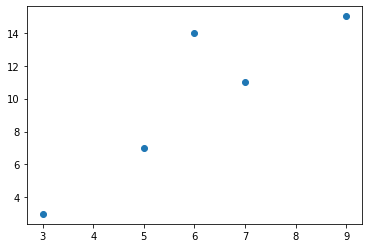

In [ ]:
#Изобразим их на графике
plt.figure()
plt.scatter(x, Y)
plt.show()

In [ ]:
#Вычислим оценки коэффициентов парной линейной регрессии по формулам
a1 = ((x - x.mean())*(Y - Y.mean())).mean()/((x - x.mean())**2).mean()
a0 = Y.mean() - a1*x.mean()
print("Модель линейной регрессии: Y^ = ", a0, " + ", a1, "* x")

Модель линейной регрессии: Y^ =  -2.0  +  2.0 * x


In [ ]:
#Дадим серию прогнозов Y^ для x от 3 до 9 с шагом 1
x_space = np.linspace(3, 9, 7)
print(x_space)
Y_pred = a0 + a1*x_space
print(Y_pred)

[3. 4. 5. 6. 7. 8. 9.]
[ 4.  6.  8. 10. 12. 14. 16.]


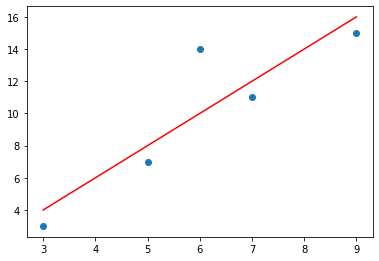

In [ ]:
#Изобразим на графике исходные данные и прогнозы 
fig  = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')
#ax.scatter(x_space, Y_pred)

In [ ]:
#Реализуем шаг градиентного спуска в модели парной лдинейной регрессии
class SimpleRegression(object):
    def __init__(self):
        self.a0 = 0
        self.a1 = 0
    def predict(self, x):
        return self.a0 + self.a1*x
    def MSE(self, x, Y):
        return ((self.predict(x)-Y)**2).mean()
    def fit(self, x, Y):
        alpha = 0.1
        dT_a0 = -2*sum((Y -self.predict(x)))
        dT_a1 = -2*sum((Y -self.predict(x))*x)
        self.a0 -= alpha*dT_a0
        self.a1 -= alpha*dT_a1

In [ ]:
#Получим прогнозы до градиентного спуска с начальными значениями параметров
regr = SimpleRegression()
print(regr.predict(3))
print(regr.predict(5))
print(regr.predict(7))
print(regr.predict(6))
print(regr.predict(9))
print(regr.MSE(x, Y))

0
0
0
0
0
120.0


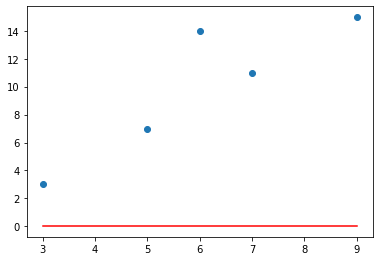

In [ ]:
#Выведем прогнозы до градиентного спуска на графике
x_space = np.linspace(3, 9, 7)
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

MSE после первого шага градиентного спуска:  183892.0


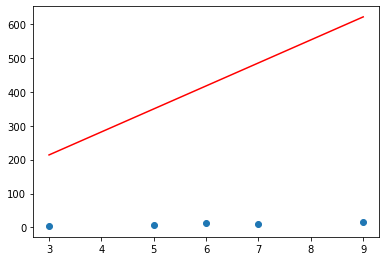

In [ ]:
#Реализуем шаг градиентного спуска
regr.fit(x, Y)
print("MSE после первого шага градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

In [ ]:
#Реализуем цикл градиентного спуска
class SimpleRegression(object):
    def __init__(self):
        self.a0 = 0
        self.a1 = 0
    def predict(self, x):
        return self.a0 + self.a1*x
    def MSE(self, x, Y):
        return ((Y - self.predict(x))**2).mean()
    def MAE(self, x, Y):
        return abs(Y - self.predict(x)).mean()
    def MAPE(self, x, Y):
        return abs((Y - self.predict(x))/Y).mean()
    def fit(self, x, Y, alpha = 0.001, epsylon = 0.01, max_steps = 5000):
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            dT_a0 = -2*sum((Y -self.predict(x)))
            dT_a1 = -2*sum((Y -self.predict(x))*x)
            self.a0 -= alpha*dT_a0
            self.a1 -= alpha*dT_a1
            new_error = self.MSE(x, Y)
            step += 1
            steps.append(step)
            errors.append(new_error)
            if new_error < epsylon:
                break
        return steps, errors

In [ ]:
#Запустим цикл градиентного спуска с заданной точностью 5
regr = SimpleRegression()
steps, errors = regr.fit(x, Y, alpha = 0.001, epsylon = 5)

5.004697916218
8.190462542210001
11.376227168202002
9.783344855206002
14.561991794194002
MSE после градиентного спуска:  4.709918696051655


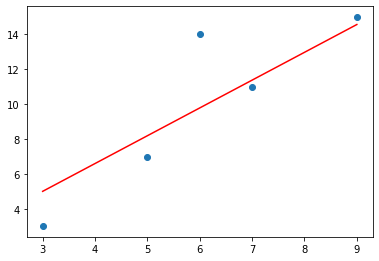

In [ ]:
#Выведем график  прогнозов и вычислим MSE
print(regr.predict(3))
print(regr.predict(5))
print(regr.predict(7))
print(regr.predict(6))
print(regr.predict(9))
print("MSE после градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

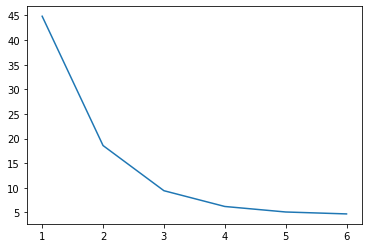

In [ ]:
#Выведем график изменения MSE в процессе градиентного спуска
plt.figure()
plt.plot(steps, errors)

In [ ]:
#Запустим цикл градиентного спуска с заданной точностью 0.05
regr = SimpleRegression()
steps, errors = regr.fit(x, Y, alpha = 0.001, epsylon = 0.05)

MSE после градиентного спуска:  4.1903709155046345


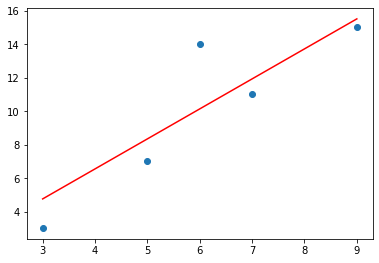

In [ ]:
#Выведем график прогнозов и вычислим MSE
print("MSE после градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
fig = plt.figure()
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.scatter(x, Y)
ax.plot(x_space, Y_pred, 'r')

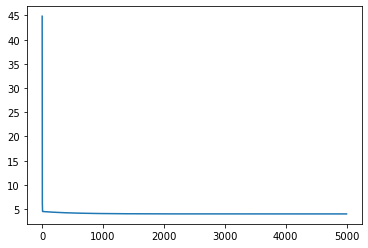

In [ ]:
#Выведем график изменения MSE в процессе градиентного спуска
plt.figure()
plt.plot(steps, errors)

MSE после градиентного спуска:  4.1903709155046345


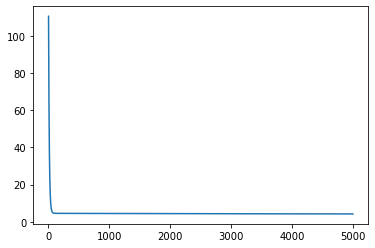

In [ ]:
#Запустим цикл градиентного спуска с разными значениями скорости обучения alpha=0.0001, 0.01, 0.1, 1, 10, ..., 
#с различной допукстимой точностью epsylon = 0.001, 0.5, 5, с различным максимальным количеством шагов max_steps
regr = SimpleRegression()
steps, errors = regr.fit(x, Y, alpha = 0.0001, epsylon = 0.01, max_steps = 5000)
print("MSE после градиентного спуска: ", regr.MSE(x, Y))
Y_pred = regr.predict(x_space)
plt.figure()
plt.plot(steps, errors)

Загрузите файл Гиперспектр кукурузы.csv (с помощью pd.read_csv).

1. Вычислите аналитическим путем оценки коэффициентов парной линейной регрессии и постройте ее график.
2. Найдите оценки параметров модели парной лиенйной регрессии с использованием метода градиентного спуска. Постройте график.
3. Оцените качество построенных моделей сравнив на графике обучающую выборку и прогнозы.


Количество точек: 50
Диапазон x: 0.69036 - 0.79914


array([0.69036, 0.69258, 0.6948 , 0.69702, 0.69924])

array([0.17, 0.19, 0.19, 0.21, 0.22])

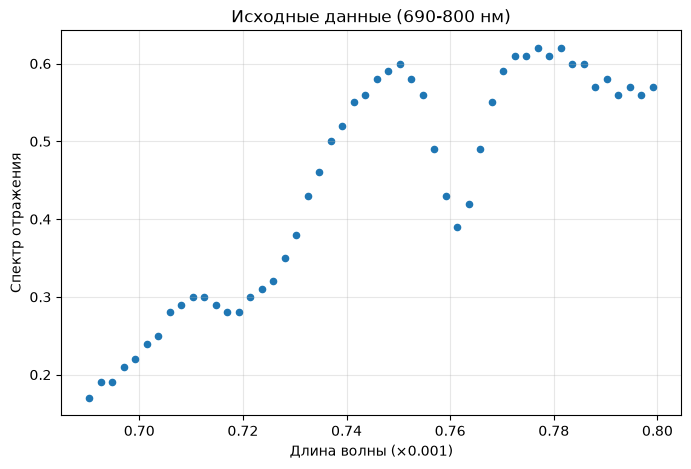


Аналитическое решение:
Y^ = -25.8179633667 + (66.5487411805) * x + (-41.9339506179) * x^2


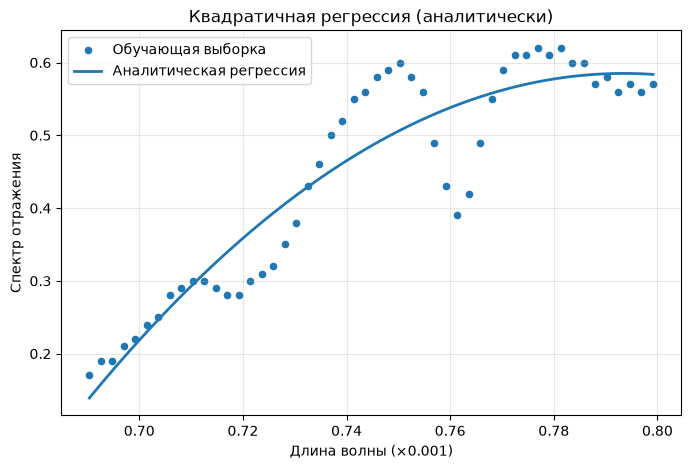


Градиентный спуск:
MSE: 0.0030012304209584327
Количество шагов: 172
Y^ = -25.8166245869 + (66.5451360854) * x + (-41.9315302788) * x^2


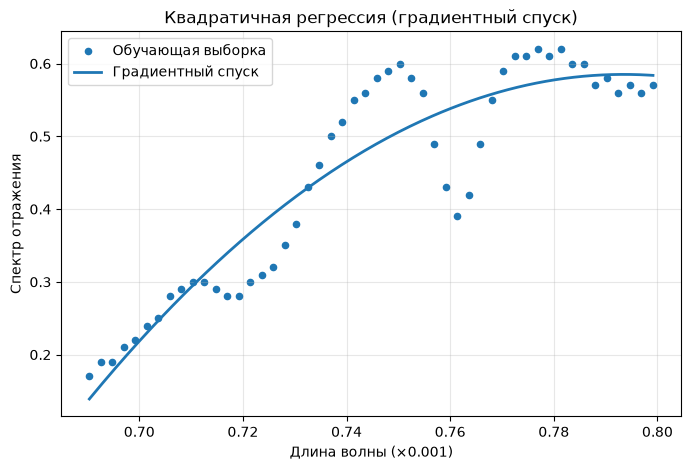

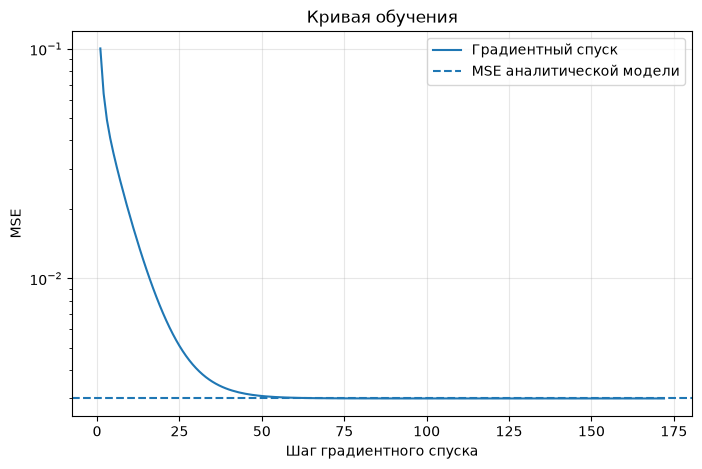

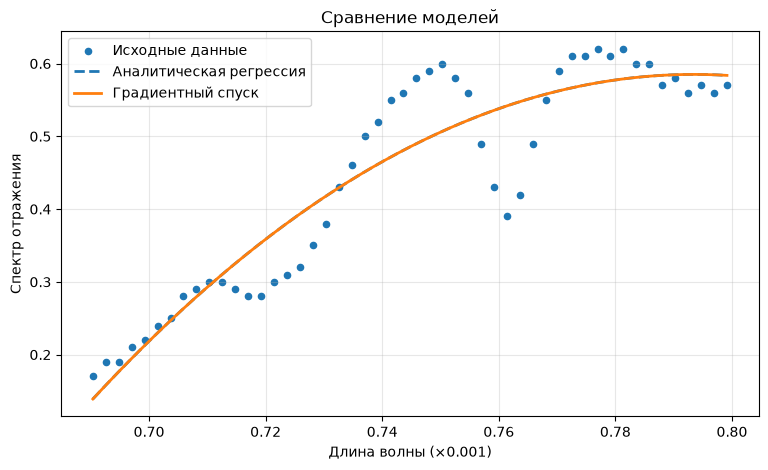


Метрика   Аналитически        Градиентный спуск   
MSE       0.003001            0.003001            
MAE       0.043038            0.043038            
MAPE, %   10.450041           10.449922           

Коэффициенты:
a0: аналитически = -25.81796337, градиентный спуск = -25.81662459
a1: аналитически = 66.54874118, градиентный спуск = 66.54513609
a2: аналитически = -41.93395062, градиентный спуск = -41.93153028


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Загружаем данные
gipers = pd.read_csv(
    r"Гиперспектр кукурузы.csv",
    sep=';',
    decimal=','
)

gipers.columns = ['wavelength', 'Spectr']

# Берём участок 690-800 нм
mask = (gipers['wavelength'] >= 690) & (gipers['wavelength'] <= 800)
data = gipers[mask].copy()

# x - длина волны, Y - спектр отражения
x = data['wavelength'].values * 0.001
Y = data['Spectr'].values

print("Количество точек:", len(x))
print("Диапазон x:", x.min(), "-", x.max())

display(x[:5], Y[:5])


# Исходные данные
plt.figure(figsize=(8, 5))
plt.scatter(x, Y, s=20)
plt.xlabel('Длина волны (×0.001)')
plt.ylabel('Спектр отражения')
plt.title('Исходные данные (690-800 нм)')
plt.grid(True, alpha=0.3)
plt.show()


# Квадратичная модель: Y = a0 + a1*x + a2*x^2
X = np.column_stack([
    np.ones_like(x),
    x,
    x**2
])

# Аналитическое решение МНК
a = np.linalg.inv(X.T @ X) @ X.T @ Y

a0, a1, a2 = a

print("\nАналитическое решение:")
print(
    f"Y^ = {a0:.10f} + "
    f"({a1:.10f}) * x + "
    f"({a2:.10f}) * x^2"
)


# Строим аналитическую модель
x_space = np.linspace(x.min(), x.max(), 300)

Y_pred_analytic = (
    a0
    + a1 * x_space
    + a2 * x_space**2
)

plt.figure(figsize=(8, 5))
plt.scatter(x, Y, s=20, label='Обучающая выборка')
plt.plot(
    x_space,
    Y_pred_analytic,
    linewidth=2,
    label='Аналитическая регрессия'
)
plt.xlabel('Длина волны (×0.001)')
plt.ylabel('Спектр отражения')
plt.title('Квадратичная регрессия (аналитически)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


class QuadraticRegression:

    def __init__(self):
        self.a0 = 0.0
        self.a1 = 0.0
        self.a2 = 0.0

    def predict(self, x):
        return self.a0 + self.a1 * x + self.a2 * x**2

    def MSE(self, x, Y):
        return np.mean((Y - self.predict(x))**2)

    def MAE(self, x, Y):
        return np.mean(np.abs(Y - self.predict(x)))

    def MAPE(self, x, Y):
        mask = Y != 0

        return np.mean(
            np.abs(
                (Y[mask] - self.predict(x[mask])) / Y[mask]
            )
        ) * 100

    def fit(
        self,
        x,
        Y,
        alpha=0.1,
        tolerance=1e-12,
        max_steps=100000
    ):
        steps = []
        errors = []

        # Масштабируем x для более стабильного обучения
        mean_x = np.mean(x)
        std_x = np.std(x)

        z = (x - mean_x) / std_x

        # Начальные коэффициенты
        b0 = 0.0
        b1 = 0.0
        b2 = 0.0

        previous_error = np.inf

        for step in range(1, max_steps + 1):

            # Предсказание
            Y_pred = b0 + b1 * z + b2 * z**2

            error = Y - Y_pred

            # Производные MSE
            d_b0 = -2 * np.mean(error)
            d_b1 = -2 * np.mean(error * z)
            d_b2 = -2 * np.mean(error * z**2)

            # Обновляем коэффициенты
            b0 -= alpha * d_b0
            b1 -= alpha * d_b1
            b2 -= alpha * d_b2

            # Новая ошибка
            new_error = np.mean(
                (
                    Y - (
                        b0
                        + b1 * z
                        + b2 * z**2
                    )
                ) ** 2
            )

            steps.append(step)
            errors.append(new_error)

            # Проверяем сходимость
            if abs(previous_error - new_error) < tolerance:
                break

            previous_error = new_error

        # Возвращаем коэффициенты к исходному x
        self.a2 = b2 / std_x**2

        self.a1 = (
            b1 / std_x
            - 2 * b2 * mean_x / std_x**2
        )

        self.a0 = (
            b0
            - b1 * mean_x / std_x
            + b2 * mean_x**2 / std_x**2
        )

        return steps, errors


# Запускаем градиентный спуск
regr = QuadraticRegression()

steps, errors = regr.fit(
    x,
    Y,
    alpha=0.1,
    tolerance=1e-12,
    max_steps=100000
)

print("\nГрадиентный спуск:")
print("MSE:", regr.MSE(x, Y))
print("Количество шагов:", len(steps))

print(
    f"Y^ = {regr.a0:.10f} + "
    f"({regr.a1:.10f}) * x + "
    f"({regr.a2:.10f}) * x^2"
)


# График модели после градиентного спуска
Y_pred_gd = (
    regr.a0
    + regr.a1 * x_space
    + regr.a2 * x_space**2
)

plt.figure(figsize=(8, 5))
plt.scatter(x, Y, s=20, label='Обучающая выборка')
plt.plot(
    x_space,
    Y_pred_gd,
    linewidth=2,
    label='Градиентный спуск'
)
plt.xlabel('Длина волны (×0.001)')
plt.ylabel('Спектр отражения')
plt.title('Квадратичная регрессия (градиентный спуск)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Объект для аналитической модели
regr_analytic = QuadraticRegression()
regr_analytic.a0 = a0
regr_analytic.a1 = a1
regr_analytic.a2 = a2


# Кривая обучения
plt.figure(figsize=(8, 5))

plt.semilogy(
    steps,
    errors,
    label='Градиентный спуск'
)

plt.axhline(
    regr_analytic.MSE(x, Y),
    linestyle='--',
    label='MSE аналитической модели'
)

plt.xlabel('Шаг градиентного спуска')
plt.ylabel('MSE')
plt.title('Кривая обучения')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Сравнение двух моделей
plt.figure(figsize=(9, 5))

plt.scatter(
    x,
    Y,
    s=20,
    label='Исходные данные'
)

plt.plot(
    x_space,
    Y_pred_analytic,
    '--',
    linewidth=2,
    label='Аналитическая регрессия'
)

plt.plot(
    x_space,
    Y_pred_gd,
    linewidth=2,
    label='Градиентный спуск'
)

plt.xlabel('Длина волны (×0.001)')
plt.ylabel('Спектр отражения')
plt.title('Сравнение моделей')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Объект для модели градиентного спуска
regr_gd = QuadraticRegression()
regr_gd.a0 = regr.a0
regr_gd.a1 = regr.a1
regr_gd.a2 = regr.a2


# Метрики качества
print("\n" + "=" * 60)

print(
    f"{'Метрика':<10}"
    f"{'Аналитически':<20}"
    f"{'Градиентный спуск':<20}"
)

print("=" * 60)

print(
    f"{'MSE':<10}"
    f"{regr_analytic.MSE(x, Y):<20.6f}"
    f"{regr_gd.MSE(x, Y):<20.6f}"
)

print(
    f"{'MAE':<10}"
    f"{regr_analytic.MAE(x, Y):<20.6f}"
    f"{regr_gd.MAE(x, Y):<20.6f}"
)

print(
    f"{'MAPE, %':<10}"
    f"{regr_analytic.MAPE(x, Y):<20.6f}"
    f"{regr_gd.MAPE(x, Y):<20.6f}"
)

print("=" * 60)


# Сравниваем коэффициенты
print("\nКоэффициенты:")
print(
    f"a0: аналитически = {a0:.8f}, "
    f"градиентный спуск = {regr.a0:.8f}"
)

print(
    f"a1: аналитически = {a1:.8f}, "
    f"градиентный спуск = {regr.a1:.8f}"
)

print(
    f"a2: аналитически = {a2:.8f}, "
    f"градиентный спуск = {regr.a2:.8f}"
)